## 1) تثبيت المكتبات

In [1]:
!pip -q install ultralytics "rembg[gpu]" diffusers transformers accelerate kagglehub opencv-python-headless arabic-reshaper python-bidi gradio scikit-learn pandas matplotlib
!apt-get -qq update > /dev/null
!apt-get -qq install -y fonts-noto-core fonts-dejavu-core libfribidi0 libraqm0 > /dev/null
print('✅ تم التثبيت. الآن: Runtime ▸ Restart session ثم شغّل من الخلية التالية (لا تعد تشغيل خلية التثبيت).')

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
✅ تم التثبيت. الآن: Runtime ▸ Restart session ثم شغّل من الخلية التالية (لا تعد تشغيل خلية التثبيت).


In [2]:
!pip -q install --force-reinstall --no-deps pillow

## 2) الإعدادات والاستيراد

In [3]:
import os, gc
os.environ.setdefault("PYTORCH_CUDA_ALLOC_CONF", "expandable_segments:True")   # يقلل تجزؤ ذاكرة GPU
import re, glob, json, random, shutil, math, copy, zipfile, socket, urllib.request
from datetime import datetime
from pathlib import Path
import numpy as np, pandas as pd, cv2
from PIL import Image, ImageDraw, ImageFont, ImageFilter, ImageOps, features
import matplotlib.pyplot as plt

try:
    import torch
    DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
except Exception:
    torch, DEVICE = None, "cpu"

SEED = 42
random.seed(SEED); np.random.seed(SEED)
if torch is not None: torch.manual_seed(SEED)

import warnings, logging
warnings.filterwarnings("ignore", category=DeprecationWarning); warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message=".*local_dir_use_symlinks.*")
for _n in ("huggingface_hub", "diffusers", "transformers"): logging.getLogger(_n).setLevel(logging.ERROR)

def free_gpu():
    gc.collect()
    if torch is not None and DEVICE == "cuda": torch.cuda.empty_cache()

def gpu_report(tag=""):
    if torch is not None and DEVICE == "cuda":
        f, t = torch.cuda.mem_get_info(); print(f"[GPU {tag}] حرة: {f/1e9:.1f} / {t/1e9:.1f} GB")

WORK = Path("/content/ad_ai") if os.path.isdir("/content") else Path("./ad_ai")
(WORK / "outputs").mkdir(parents=True, exist_ok=True)
RUN_ID = datetime.now().strftime("%Y%m%d_%H%M%S")
print("Device:", DEVICE, "| Work dir:", WORK, "| Run:", RUN_ID)
if DEVICE == "cpu": print("⚠️ لا يوجد GPU: سيعمل النظام لكن بخلفيات إجرائية، والتدريب سيكون بطيئاً.")

Device: cuda | Work dir: /content/ad_ai | Run: 20261125_183258


## 3) ربط Google Drive (حفظ تلقائي للنتائج والنماذج)

In [4]:
USE_DRIVE = True          # ← غيّرها إلى False لتعطيل الحفظ في درايف
DRIVE_DIR = None

def mount_drive():
    global DRIVE_DIR
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        DRIVE_DIR = Path("/content/drive/MyDrive/ProductAdAI")
        for sub in ("ads", "models", "runs"): (DRIVE_DIR / sub).mkdir(parents=True, exist_ok=True)
        print("✅ تم ربط Drive. مجلد الحفظ:", DRIVE_DIR)
    except Exception as e:
        DRIVE_DIR = None
        print("⚠️ تعذر ربط Drive، سيتم الحفظ محلياً فقط:", e)

def drive_copy(src, sub=""):
    # ينسخ ملفاً إلى Drive فوراً (يُستدعى تلقائياً بعد كل إعلان وبعد التدريب)
    if DRIVE_DIR is None or not Path(src).exists(): return None
    try:
        dst = DRIVE_DIR / sub; dst.mkdir(parents=True, exist_ok=True)
        out = dst / Path(src).name; shutil.copy2(src, out); return out
    except Exception as e:
        print("تعذر النسخ إلى Drive:", e); return None

if USE_DRIVE: mount_drive()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
✅ تم ربط Drive. مجلد الحفظ: /content/drive/MyDrive/ProductAdAI


## 4) تنزيل البيانات من Kaggle

In [5]:
import kagglehub
DATASET = "paramaggarwal/fashion-product-images-small"

def download_dataset():
    try:
        return kagglehub.dataset_download(DATASET)
    except Exception as e:
        print("تعذر التنزيل المباشر:", e)
        print("ارفع ملف kaggle.json (من Kaggle ▸ Settings ▸ API ▸ Create New Token)")
        from google.colab import files
        files.upload()
        os.makedirs(os.path.expanduser("~/.kaggle"), exist_ok=True)
        shutil.move("kaggle.json", os.path.expanduser("~/.kaggle/kaggle.json"))
        os.chmod(os.path.expanduser("~/.kaggle/kaggle.json"), 0o600)
        return kagglehub.dataset_download(DATASET)

DATA_ROOT = Path(download_dataset())
STYLES_CSV = next(DATA_ROOT.rglob("styles.csv"))
IMG_DIR = next(p for p in DATA_ROOT.rglob("images") if p.is_dir())
print("CSV:", STYLES_CSV); print("Images:", IMG_DIR, len(list(IMG_DIR.glob("*.jpg"))), "صورة")

Using Colab cache for faster access to the 'fashion-product-images-small' dataset.
CSV: /kaggle/input/fashion-product-images-small/styles.csv
Images: /kaggle/input/fashion-product-images-small/images 44441 صورة


## 5) تجهيز البيانات (حتى 40 نوع منتج، 900 صورة لكل نوع)

In [6]:
from sklearn.model_selection import train_test_split

styles = pd.read_csv(STYLES_CSV, on_bad_lines="skip")
styles["path"] = styles["id"].astype(str).map(lambda i: str(IMG_DIR / f"{i}.jpg"))
styles = styles[styles["path"].map(os.path.exists)].dropna(subset=["articleType"]).reset_index(drop=True)

def to_group(r):
    if r.masterCategory == "Footwear": return "footwear"
    if r.subCategory == "Bags": return "bag"
    if r.masterCategory == "Apparel": return "clothing"
    return "accessory"
styles["group"] = styles.apply(to_group, axis=1)

vc = styles.articleType.value_counts()
KEEP = vc[vc >= 300].index.tolist()[:40]
df = styles[styles.articleType.isin(KEEP)]
df = df.groupby("articleType", group_keys=False).apply(lambda g: g.sample(min(len(g), 900), random_state=SEED)).reset_index(drop=True)

CLASSES = sorted(KEEP)
CLS2IDX = {c: i for i, c in enumerate(CLASSES)}
TYPE2GROUP = df.groupby("articleType")["group"].agg(lambda s: s.mode()[0]).to_dict()
train_df, val_df = train_test_split(df, test_size=0.15, stratify=df.articleType, random_state=SEED)
print(len(CLASSES), "نوع |", len(train_df), "تدريب |", len(val_df), "تحقق"); print(df.groupby("group").size())

31 نوع | 18090 تدريب | 3193 تحقق
group
accessory    6217
bag          1623
clothing     7809
footwear     5634
dtype: int64


## 6) المصنّف: EfficientNet-B0 (تدريب، أو تحميل نسخة محفوظة من Drive لتوفير الوقت)

In [7]:
import torch.nn as nn, torchvision
from torchvision import transforms as T
from torch.utils.data import Dataset, DataLoader

FORCE_RETRAIN = False     # True لإعادة التدريب حتى لو وُجدت نسخة محفوظة
EPOCHS = 6
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
tf_eval = T.Compose([T.Resize((224, 224)), T.ToTensor(), T.Normalize(MEAN, STD)])
tf_train = T.Compose([T.RandomResizedCrop(224, scale=(0.75, 1.0), ratio=(0.9, 1.1)), T.RandomHorizontalFlip(),
                      T.RandomRotation(8, fill=255), T.ColorJitter(0.25, 0.25, 0.25, 0.02), T.ToTensor(), T.Normalize(MEAN, STD)])
CKPT = WORK / "product_classifier.pt"

def build_model(n, pretrained=True):
    w = torchvision.models.EfficientNet_B0_Weights.DEFAULT if pretrained else None
    m = torchvision.models.efficientnet_b0(weights=w)
    m.classifier[1] = nn.Linear(m.classifier[1].in_features, n)
    return m.to(DEVICE)

class ProductDS(Dataset):
    def __init__(self, frame, tf): self.f, self.tf = frame.reset_index(drop=True), tf
    def __len__(self): return len(self.f)
    def __getitem__(self, i):
        r = self.f.iloc[i]
        return self.tf(Image.open(r.path).convert("RGB")), CLS2IDX[r.articleType]

def try_load_ckpt():
    paths = ([DRIVE_DIR / "models" / CKPT.name] if DRIVE_DIR else []) + [CKPT]
    for p in paths:
        if p.exists():
            ck = torch.load(p, map_location=DEVICE, weights_only=False)
            if ck.get("classes") == CLASSES: print("تم تحميل نموذج محفوظ من:", p); return ck
    return None

def train_classifier():
    model = build_model(len(CLASSES))
    train_dl = DataLoader(ProductDS(train_df, tf_train), batch_size=64, shuffle=True, num_workers=2, drop_last=True)
    val_dl = DataLoader(ProductDS(val_df, tf_eval), batch_size=128, num_workers=2)
    opt = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=1.5e-3, steps_per_epoch=len(train_dl), epochs=EPOCHS)
    scaler = torch.amp.GradScaler("cuda", enabled=(DEVICE == "cuda"))
    loss_fn = nn.CrossEntropyLoss(label_smoothing=0.1)

    def evaluate():
        model.eval(); ys, ps = [], []
        with torch.no_grad():
            for x, y in val_dl:
                ps += model(x.to(DEVICE)).argmax(1).cpu().tolist(); ys += y.tolist()
        return float(np.mean(np.array(ys) == np.array(ps))), ys, ps

    best_acc, best_state = 0, None
    for ep in range(EPOCHS):
        model.train(); tot = 0
        for x, y in train_dl:
            x, y = x.to(DEVICE), y.to(DEVICE); opt.zero_grad()
            with torch.autocast(device_type="cuda", enabled=(DEVICE == "cuda")):
                loss = loss_fn(model(x), y)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step(); tot += loss.item()
        acc, ys, ps = evaluate()
        if acc > best_acc: best_acc, best_state = acc, copy.deepcopy(model.state_dict())
        print(f"epoch {ep+1}/{EPOCHS}  loss={tot/len(train_dl):.3f}  val_acc={acc:.3f}  best={best_acc:.3f}")
    model.load_state_dict(best_state)
    acc, ys, ps = evaluate()

    from sklearn.metrics import classification_report, confusion_matrix
    rep = classification_report(ys, ps, target_names=CLASSES, digits=3, output_dict=True, zero_division=0)
    cm = confusion_matrix(ys, ps)
    pairs = sorted([(cm[i, j], CLASSES[i], CLASSES[j]) for i in range(len(CLASSES)) for j in range(len(CLASSES)) if i != j], reverse=True)[:8]
    print(f"\n✅ أفضل دقة تحقق: {acc:.3f}\nأكثر حالات الالتباس:"); [print(f"  {a}  ←→ {b}  ({n}x)") for n, a, b in [(p[0], p[1], p[2]) for p in pairs]]
    metrics = {"val_acc": acc, "per_class_f1": {c: rep[c]["f1-score"] for c in CLASSES}, "top_confusions": [list(map(str, p)) for p in pairs]}
    torch.save({"state": model.state_dict(), "classes": CLASSES, "type2group": TYPE2GROUP}, CKPT)
    (WORK / "classifier_metrics.json").write_text(json.dumps(metrics, ensure_ascii=False, indent=1))
    drive_copy(CKPT, "models"); drive_copy(WORK / "classifier_metrics.json", "models")     # حفظ فوري في Drive
    return model

ck = None if FORCE_RETRAIN else try_load_ckpt()
if ck is not None:
    clf = build_model(len(CLASSES), pretrained=False); clf.load_state_dict(ck["state"]); clf.eval()
else:
    clf = train_classifier(); free_gpu()

تم تحميل نموذج محفوظ من: /content/drive/MyDrive/ProductAdAI/models/product_classifier.pt


## 7) تحليل الصورة: تصنيف بالـ TTA + كشف YOLO11

In [8]:
from ultralytics import YOLO
yolo = YOLO("yolo11s-seg.pt")   # كشف + قناع (COCO): لتحديد موضع المنتج وكخطة بديلة للمنتجات غير الموجودة في بيانات التدريب

COCO_GROUP = {"handbag": "bag", "backpack": "bag", "suitcase": "bag", "tie": "accessory", "umbrella": "accessory",
              "bottle": "generic", "cup": "generic", "vase": "generic", "clock": "generic", "cell phone": "generic",
              "laptop": "generic", "book": "generic", "teddy bear": "generic", "bowl": "generic"}

def to_dataset_style(rgba, margin=0.10):
    # يضع المنتج المعزول على خلفية بيضاء بنسبة 3:4 (نفس شكل بيانات التدريب) ← يرفع دقة التصنيف كثيراً
    w, h = rgba.size
    cw = max(w * (1 + 2*margin), h * (1 + 2*margin) * 0.75); ch = cw / 0.75
    cv_ = Image.new("RGB", (int(cw), int(ch)), (255, 255, 255))
    cv_.paste(rgba.convert("RGB"), ((int(cw) - w) // 2, (int(ch) - h) // 2), rgba.split()[3])
    return cv_

@torch.no_grad()
def classify(img, topk=3):
    clf.eval()
    x = tf_eval(img.convert("RGB")).unsqueeze(0).to(DEVICE)
    xs = torch.cat([x, torch.flip(x, [3])])                       # TTA: الصورة + انعكاسها
    p = torch.softmax(clf(xs), 1).mean(0).cpu()
    v, i = p.topk(topk)
    return [(CLASSES[j], float(s)) for s, j in zip(v, i)]

def detect(img, conf=0.25):
    r = yolo.predict(img.convert("RGB"), conf=conf, verbose=False)[0]
    out = [(r.names[int(b.cls)], float(b.conf), tuple(map(int, b.xyxy[0].tolist()))) for b in r.boxes]
    return sorted(out, key=lambda t: -(t[2][2]-t[2][0]) * (t[2][3]-t[2][1]))

def analyze_product(img, product_rgba=None, min_conf=0.55):
    probe = to_dataset_style(product_rgba) if product_rgba is not None else img
    top3 = classify(probe); dets = detect(img)
    ptype, conf = top3[0]
    group = TYPE2GROUP.get(ptype, "generic")
    bbox, coco = (dets[0][2], dets[0][0]) if dets else (None, None)
    if conf < min_conf and coco in COCO_GROUP: ptype, group = coco, COCO_GROUP[coco]
    elif conf < min_conf: group = "generic"
    return {"type": ptype, "group": group, "confidence": conf, "top3": top3, "coco": coco, "bbox": bbox}

## 8) عزل المنتج: BiRefNet + تنقية القناع + إزالة هالة الحواف

In [9]:
def upscale_min(img, target=768):
    w, h = img.size
    if max(w, h) >= target: return img
    f = target / max(w, h); return img.resize((int(w * f), int(h * f)), Image.LANCZOS)

def clean_alpha(alpha, keep_ratio=0.05):
    _, b = cv2.threshold(alpha, 127, 255, cv2.THRESH_BINARY)
    n, lab, stats, _ = cv2.connectedComponentsWithStats(b)
    if n > 1:
        areas = stats[1:, cv2.CC_STAT_AREA]
        ok = [i + 1 for i, a in enumerate(areas) if a >= keep_ratio * areas.max()]
        b = np.isin(lab, ok).astype(np.uint8) * 255
    b = cv2.morphologyEx(b, cv2.MORPH_CLOSE, np.ones((5, 5), np.uint8))
    soft = cv2.GaussianBlur(alpha, (3, 3), 0)
    out = np.minimum(soft, cv2.dilate(b, np.ones((3, 3), np.uint8)))
    out[out < 18] = 0
    return out

def defringe(arr):
    # يستبدل ألوان بكسلات الحافة بألوان من داخل المنتج لإزالة الهالة (لون الخلفية القديمة)
    rgb, a = arr[..., :3], arr[..., 3]
    solid = cv2.erode((a > 240).astype(np.uint8), np.ones((5, 5), np.uint8)).astype(np.float32)
    ring = (a > 5) & (solid == 0)
    if not ring.any(): return arr
    k = (17, 17)
    num = cv2.blur(rgb.astype(np.float32) * solid[..., None], k); den = cv2.blur(solid, k)[..., None]
    fill = num / np.maximum(den, 1e-4)
    use = ring & (den[..., 0] > 0.02)
    rgb[use] = np.clip(0.75 * fill[use] + 0.25 * rgb[use], 0, 255).astype(np.uint8)
    arr[..., :3] = rgb
    return arr

# ---- model ----
from rembg import remove, new_session

SEG_ON_CPU = True    # العزل على المعالج: لا يستهلك أي ذاكرة GPU (أبطأ بعدة ثوانٍ لكنه يمنع OutOfMemory)

def load_seg():
    prov = ["CPUExecutionProvider"] if SEG_ON_CPU else None
    for name in ("birefnet-general-lite", "isnet-general-use"):
        try:
            sess = new_session(name, providers=prov) if prov else new_session(name)
            print("نموذج العزل:", name, "(CPU)" if SEG_ON_CPU else "(GPU)"); return sess
        except Exception as e:
            print(f"تعذر تحميل {name}:", str(e)[:100])
SEG_SESSION = load_seg()

def isolate_product(img, pad=6):
    rgba = remove(upscale_min(img.convert("RGB")), session=SEG_SESSION)
    a = np.array(rgba.convert("RGBA"))
    a[..., 3] = clean_alpha(a[..., 3])
    a = defringe(a)
    ys, xs = np.where(a[..., 3] > 10)
    if len(xs) == 0: return Image.fromarray(a)
    x0, x1 = max(xs.min() - pad, 0), min(xs.max() + pad, a.shape[1])
    y0, y1 = max(ys.min() - pad, 0), min(ys.max() + pad, a.shape[0])
    return Image.fromarray(a[y0:y1, x0:x1])

تعذر تحميل birefnet-general-lite: HTTPSConnectionPool(host='github.com', port=443): Read timed out. (read timeout=30)
تعذر تحميل isnet-general-use: HTTPSConnectionPool(host='github.com', port=443): Read timed out. (read timeout=30)


## 9) تحسين جودة الصورة

In [10]:
def enhance_product(rgba, wb=True, clahe=True, denoise=True, sharpen=True, target_L=135, upscale_to=1000):
    arr = np.array(rgba.convert("RGBA"))
    rgb, a = arr[..., :3].copy(), arr[..., 3]
    m = a > 128
    if m.sum() < 10: return rgba
    h, w = a.shape
    if max(h, w) < upscale_to:
        f = upscale_to / max(h, w)
        rgb = cv2.resize(rgb, (int(w * f), int(h * f)), interpolation=cv2.INTER_LANCZOS4)
        a = cv2.resize(a, (int(w * f), int(h * f)), interpolation=cv2.INTER_LANCZOS4); m = a > 128
    if wb:
        means = rgb[m].mean(0); gains = np.clip(means.mean() / (means + 1e-6), 0.85, 1.2)
        rgb = np.clip(rgb.astype(np.float32) * gains, 0, 255).astype(np.uint8)
    lab = cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB); L = lab[..., 0]
    if clahe:   # نملأ المنطقة الشفافة بمتوسط المنتج كي لا تلوّث مدرّجات CLAHE، ثم ندمج 50% مع الأصل
        Lf = L.copy(); Lf[~m] = int(L[m].mean())
        L = cv2.addWeighted(cv2.createCLAHE(clipLimit=1.6, tileGridSize=(8, 8)).apply(Lf), 0.5, L, 0.5, 0)
    shift = np.clip((target_L - L[m].mean()) * 0.5, -25, 25)
    lab[..., 0] = np.clip(L.astype(np.float32) + shift, 0, 255).astype(np.uint8)
    rgb = cv2.cvtColor(lab, cv2.COLOR_LAB2RGB)
    if denoise: rgb = cv2.fastNlMeansDenoisingColored(rgb, None, 3, 3, 7, 21)
    if sharpen:   # قوة الحدّة تتكيّف مع درجة ضبابية الصورة
        lap = cv2.Laplacian(cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY), cv2.CV_64F).var()
        amt = 0.9 if lap < 150 else (0.6 if lap < 600 else 0.4)
        blur = cv2.GaussianBlur(rgb, (0, 0), 1.2)
        rgb = cv2.addWeighted(rgb, 1 + amt, blur, -amt, 0)
    return Image.fromarray(np.dstack([rgb, a]))

def dominant_color(rgba):
    arr = np.array(rgba.convert("RGBA")); px = arr[arr[..., 3] > 200][:, :3].astype(np.float32)
    if len(px) < 50: return (212, 175, 55)
    px = px[np.random.RandomState(0).choice(len(px), min(len(px), 4000), replace=False)]
    _, lab, cen = cv2.kmeans(px, 3, None, (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 20, 1.0), 3, cv2.KMEANS_PP_CENTERS)
    return tuple(int(v) for v in cen[int(np.argmax([max(c) - min(c) for c in cen]))])

## 10) توليد الخلفية الإعلانية (SDXL-Turbo + تحسين الدقة)

In [11]:
STYLES = {
    "luxury":  ("dark marble podium, soft golden rim light, elegant luxury backdrop, subtle bokeh", ((20, 18, 24), (70, 56, 40))),
    "minimal": ("clean minimal studio, pastel seamless backdrop, soft diffused light, empty round podium", ((235, 230, 225), (200, 190, 185))),
    "summer":  ("bright summer scene, warm sunlight, tropical leaf shadows, sandy podium", ((255, 214, 160), (255, 140, 120))),
    "neon":    ("futuristic dark studio, neon magenta and cyan lights, glossy reflective floor", ((10, 8, 30), (90, 20, 110))),
    "nature":  ("soft green nature background, wooden platform, morning light, blurred foliage", ((170, 200, 160), (70, 110, 80))),
}
GROUP_HINT = {"footwear": "sneaker showcase stage", "bag": "fashion boutique display", "clothing": "fashion editorial set",
              "accessory": "jewelry display table", "generic": "product photography set"}
OFFLOAD = True    # يبقي نموذج SDXL في ذاكرة النظام ويرسل كل جزء إلى GPU عند الحاجة فقط (ذاكرة GPU ≈ 3-4GB بدل 8GB+)
HQ_BG = False     # تمريرة ثانية لرفع دقة الخلفية: فعّلها (True) فقط إن كانت لديك ذاكرة GPU وفيرة

def build_bg_prompt(style, group):
    return f"empty {GROUP_HINT.get(group, GROUP_HINT['generic'])}, {STYLES[style][0]}, professional advertising photography background, empty center, no objects, no text, no people, sharp, high quality"

def gen_dims(size):
    r = size[1] / size[0]
    if r < 1.1: return (512, 512), (768, 768)
    if r < 1.5: return (512, 640), (768, 960)
    return (512, 896), (768, 1344)

_pipe = _i2i = None
def load_diffusion():
    global _pipe
    if _pipe is None and DEVICE == "cuda":
        from diffusers import AutoPipelineForText2Image
        _pipe = AutoPipelineForText2Image.from_pretrained("stabilityai/sdxl-turbo", torch_dtype=torch.float16, variant="fp16")
        if OFFLOAD: _pipe.enable_model_cpu_offload()
        else: _pipe.to("cuda")
        for fn in ("enable_vae_tiling", "enable_vae_slicing"):
            try: getattr(_pipe, fn)()
            except Exception: pass
    return _pipe

def procedural_background(style, size, seed=0):
    W, H = size; rng = np.random.RandomState(seed)
    c1, c2 = [np.array(c, np.float32) for c in STYLES[style][1]]
    t = np.linspace(0, 1, H)[:, None, None]
    bg = (c1 * (1 - t) + c2 * t) * np.ones((H, W, 3), np.float32)
    yy, xx = np.mgrid[0:H, 0:W]
    bg = bg + np.exp(-(((xx - W/2) / (W*0.45))**2 + ((yy - H*0.55) / (H*0.35))**2))[..., None] * 60
    for _ in range(18):
        cx, cy, r = rng.randint(0, W), rng.randint(0, int(H*0.6)), rng.randint(20, 80)
        ov = bg.copy(); cv2.circle(ov, (cx, cy), r, (255, 255, 255), -1); bg = cv2.addWeighted(ov, 0.07, bg, 0.93, 0)
    bg = cv2.GaussianBlur(bg, (0, 0), 6)
    vig = 1 - 0.35 * (((xx - W/2) / (W/2))**2 + ((yy - H/2) / (H/2))**2)
    return Image.fromarray(np.clip(bg * np.clip(vig, 0.5, 1)[..., None], 0, 255).astype(np.uint8))

def add_grain(img, amount=3.0, seed=0):
    a = np.array(img).astype(np.float32); n = np.random.RandomState(seed).normal(0, amount, a.shape[:2])[..., None]
    return Image.fromarray(np.clip(a + n, 0, 255).astype(np.uint8))

def generate_background(style="luxury", group="generic", size=(1080, 1350), seed=None):
    seed = seed if seed is not None else random.randint(0, 10**6)
    pipe = load_diffusion()
    if pipe is None: return procedural_background(style, size, seed)
    (w1, h1), (w2, h2) = gen_dims(size); prompt = build_bg_prompt(style, group)
    g = torch.Generator("cuda").manual_seed(seed)
    free_gpu()
    try:
        img = pipe(prompt=prompt, num_inference_steps=4, guidance_scale=0.0, width=w1, height=h1, generator=g).images[0]
    except torch.cuda.OutOfMemoryError:
        free_gpu(); print("⚠️ نفدت ذاكرة GPU أثناء توليد الخلفية؛ استُخدمت خلفية إجرائية بدلاً منها."); return procedural_background(style, size, seed)
    if HQ_BG:
        try:
            global _i2i
            if _i2i is None:
                from diffusers import AutoPipelineForImage2Image
                _i2i = AutoPipelineForImage2Image.from_pipe(pipe)
            img = _i2i(prompt=prompt, image=img.resize((w2, h2), Image.LANCZOS), strength=0.45, num_inference_steps=4,
                       guidance_scale=0.0, generator=g).images[0]
        except Exception as e:
            print("تخطي تحسين الدقة:", str(e)[:120]); free_gpu()
    return add_grain(img.resize(size, Image.LANCZOS), 2.5, seed)

## 11) الدمج الواقعي (لون + إضاءة + إضاءة الحواف + ظلال + انعكاس)

In [12]:
def match_color(prod_rgba, bg_patch, strength=0.15, l_strength=0.06):
    arr = np.array(prod_rgba); m = arr[..., 3] > 128
    if m.sum() == 0: return prod_rgba
    lab = cv2.cvtColor(arr[..., :3], cv2.COLOR_RGB2LAB).astype(np.float32)
    bg_lab = cv2.cvtColor(np.array(bg_patch.convert("RGB")), cv2.COLOR_RGB2LAB).reshape(-1, 3).mean(0)
    for ch, s in ((0, l_strength), (1, strength), (2, strength)):
        lab[..., ch] += s * (bg_lab[ch] - lab[..., ch][m].mean())
    arr[..., :3] = cv2.cvtColor(np.clip(lab, 0, 255).astype(np.uint8), cv2.COLOR_LAB2RGB)
    return Image.fromarray(arr)

def light_wrap(p, bg_patch, amount=0.14):
    # يمزج لون الخلفية المحيطة قليلاً على حواف المنتج ليبدو "داخل" المشهد
    arr = np.array(p).astype(np.float32); a = arr[..., 3] / 255
    edge = np.clip(a - cv2.GaussianBlur(a, (0, 0), max(2.0, p.size[0] * 0.004)), 0, 1); edge = edge / (edge.max() + 1e-6)
    bgm = np.array(bg_patch.convert("RGB").resize(p.size).filter(ImageFilter.GaussianBlur(20))).astype(np.float32)
    w = (amount * edge)[..., None]
    arr[..., :3] = arr[..., :3] * (1 - w) + bgm * w
    return Image.fromarray(arr.astype(np.uint8))

def composite_product(bg, product, scale=0.70, anchor=(0.5, 0.60), color_strength=0.15, reflection=True):
    W, H = bg.size
    bb = product.split()[3].point(lambda v: 255 if v > 10 else 0).getbbox()
    if bb: product = product.crop(bb)
    pw, ph = product.size
    f = min(W * scale / pw, H * 0.50 / ph)
    p = product.resize((max(1, int(pw * f)), max(1, int(ph * f))), Image.LANCZOS)
    pw, ph = p.size
    x, y = int(W * anchor[0] - pw / 2), int(H * anchor[1] - ph / 2)
    patch = bg.crop((x, y, x + pw, y + ph))
    p = light_wrap(match_color(p, patch, color_strength), patch)
    canvas = bg.convert("RGBA"); alpha = p.split()[3]
    black = Image.new("RGB", (W, H), (0, 0, 0))

    if reflection and y + ph < H:
        refl = ImageOps.flip(p); ra = np.array(refl.split()[3]).astype(np.float32)
        refl.putalpha(Image.fromarray((ra * np.linspace(0.30, 0, ra.shape[0])[:, None]).astype(np.uint8)))
        canvas.alpha_composite(refl.filter(ImageFilter.GaussianBlur(2)), (x, y + ph - int(ph * 0.02)))

    drop = Image.new("L", (W, H), 0); drop.paste(alpha, (x + int(pw * 0.03), y + int(ph * 0.05)))
    drop = drop.filter(ImageFilter.GaussianBlur(25)).point(lambda v: int(v * 0.30))
    canvas.alpha_composite(Image.merge("RGBA", (*black.split(), drop)))

    ch = max(10, int(ph * 0.10)); contact = Image.new("L", (W, H), 0)
    contact.paste(alpha.resize((pw, ch)), (x, y + ph - ch // 2))
    contact = contact.filter(ImageFilter.GaussianBlur(10)).point(lambda v: int(v * 0.65))
    canvas.alpha_composite(Image.merge("RGBA", (*black.split(), contact)))
    canvas.alpha_composite(p, (x, y))
    return canvas.convert("RGB")

## 12) النصوص: عربي/إنجليزي، تشكيل الحروف، اتجاه الكتابة (RTL)، خط Tajawal

In [13]:
try:
    import arabic_reshaper
    from bidi.algorithm import get_display
except Exception:
    arabic_reshaper = None

RAQM = features.check("raqm")      # إن وُجد raqm يتولى تشكيل العربية واتجاهها بنفسه
AR = re.compile(r"[\u0600-\u06FF]")
AR_DIGITS = str.maketrans("0123456789", "٠١٢٣٤٥٦٧٨٩")
print("Raqm:", RAQM, "| arabic_reshaper:", arabic_reshaper is not None)

FONT_DIR = WORK / "fonts"; FONT_DIR.mkdir(exist_ok=True)
FONT_URLS = {n: f"https://github.com/google/fonts/raw/main/ofl/tajawal/{n}" for n in ("Tajawal-Bold.ttf", "Tajawal-Regular.ttf")}
def ensure_fonts():
    socket.setdefaulttimeout(15)
    for name, url in FONT_URLS.items():
        p = FONT_DIR / name
        if not p.exists():
            try: urllib.request.urlretrieve(url, p)
            except Exception as e: print("تعذر تنزيل الخط", name, "← سيُستخدم خط بديل")
ensure_fonts()

def shape(t):
    if not AR.search(t) or RAQM or arabic_reshaper is None: return t
    return get_display(arabic_reshaper.reshape(t))

def find_font(text, bold=True):
    tj = FONT_DIR / ("Tajawal-Bold.ttf" if bold else "Tajawal-Regular.ttf")
    if AR.search(text):      # خطوط احتياطية تدعم العربية (DejaVu أولاً مع التشكيل اليدوي لأنه يحوي أشكال العرض)
        sys_pats = (["DejaVuSans-Bold.ttf"] if bold else ["DejaVuSans.ttf"]) + ["NotoNaskhArabic*.ttf", "NotoSansArabic*.ttf"] if not RAQM \
                   else ["NotoNaskhArabic*.ttf", "NotoSansArabic*.ttf", "DejaVuSans-Bold.ttf" if bold else "DejaVuSans.ttf"]
    else:
        sys_pats = ["NotoSans-Bold.ttf", "DejaVuSans-Bold.ttf"] if bold else ["NotoSans-Regular.ttf", "DejaVuSans.ttf"]
    if tj.exists() and (RAQM or not AR.search(text)): return str(tj)
    for p in sys_pats:
        hit = glob.glob(f"/usr/share/fonts/**/{p}", recursive=True)
        if hit: return hit[0]
    return str(tj) if tj.exists() else None

def get_font(text, size, bold=True):
    path = find_font(text, bold)
    if not path: return ImageFont.load_default(size)
    try:
        eng = ImageFont.Layout.RAQM if RAQM else ImageFont.Layout.BASIC
        f = ImageFont.truetype(path, size, layout_engine=eng)
    except Exception:
        f = ImageFont.truetype(path, size)
    if "[" in Path(path).name and bold:
        try: f.set_variation_by_name("Bold")
        except Exception: pass
    return f

def fit_font(text, max_w, max_size, min_size=26, bold=True):
    s = max_size
    while s > min_size:
        f = get_font(text, s, bold); l, t, r, b = f.getbbox(shape(text))
        if r - l <= max_w: return f
        s -= 2
    return get_font(text, min_size, bold)

def gradient_overlay(img, top=0.62, bottom=0.62):
    W, H = img.size; a = np.zeros((H, W), np.float32)
    a[: int(H*0.34)] = np.linspace(top, 0, int(H*0.34))[:, None]
    a[int(H*0.72):] = np.linspace(0, bottom, H - int(H*0.72))[:, None]
    ov = Image.merge("RGBA", (*Image.new("RGB", (W, H), (0, 0, 0)).split(), Image.fromarray((a * 255).astype(np.uint8))))
    return Image.alpha_composite(img.convert("RGBA"), ov)

def monogram_logo(brand, color, d=120):
    im = Image.new("RGBA", (d, d), (0, 0, 0, 0)); dr = ImageDraw.Draw(im)
    dr.ellipse((0, 0, d-1, d-1), fill=tuple(color) + (255,))
    ch = shape(brand[:1].upper()); f = get_font(ch, int(d*0.55))
    l, t, r, b = dr.textbbox((0, 0), ch, font=f)
    dr.text(((d-(r-l))/2 - l, (d-(b-t))/2 - t), ch, font=f, fill=(255, 255, 255, 255))
    return im

def add_ad_text(img, title, tagline="", price="", cta="", brand="", logo=None, accent=(212, 175, 55), rtl=None, ar_digits=False):
    if ar_digits: price, title, tagline = price.translate(AR_DIGITS), title.translate(AR_DIGITS), tagline.translate(AR_DIGITS)
    if rtl is None: rtl = bool(AR.search(" ".join([title, tagline, brand, cta])))
    img = gradient_overlay(img); W, H = img.size; dr = ImageDraw.Draw(img); M = int(W * 0.06)
    white = (255, 255, 255, 255)

    if logo is None and brand: logo = monogram_logo(brand, accent)
    if logo is not None:                                        # الشعار + اسم العلامة (يُعكس في RTL)
        lg = logo.convert("RGBA"); lg.thumbnail((130, 130))
        lx = W - M - lg.width if rtl else M
        img.alpha_composite(lg, (lx, M))
        if brand:
            bf = get_font(brand, 34); t = shape(brand); tw = dr.textlength(t, font=bf)
            dr.text((lx - 18 - tw if rtl else lx + lg.width + 18, M + (lg.height - 34) // 2), t, font=bf, fill=white)
    if title:
        f = fit_font(title, W - 2*M, 96); t = shape(title); w = dr.textlength(t, font=f)
        dr.text(((W - w) / 2, int(H * 0.15)), t, font=f, fill=white, stroke_width=1, stroke_fill=(0, 0, 0, 90))
    if tagline:
        f = fit_font(tagline, W - 2*M, 42, bold=False); t = shape(tagline); w = dr.textlength(t, font=f)
        dr.text(((W - w) / 2, int(H * 0.15) + 112), t, font=f, fill=(240, 240, 240, 255))
    if price:                                                   # السعر: يمين في RTL ويسار في LTR
        f = fit_font(price, int(W * 0.36), 76); t = shape(price); l, tt, r, b = dr.textbbox((0, 0), t, font=f)
        pw, ph = r - l + 70, b - tt + 44; x0 = W - M - pw if rtl else M; y0 = H - M - ph
        dr.rounded_rectangle((x0, y0, x0 + pw, y0 + ph), radius=ph // 2, fill=tuple(accent) + (255,))
        lum = 0.299*accent[0] + 0.587*accent[1] + 0.114*accent[2]
        dr.text((x0 + 35 - l, y0 + 22 - tt), t, font=f, fill=(20, 20, 20, 255) if lum > 140 else white)
    if cta:
        f = fit_font(cta, int(W * 0.34), 44); t = shape(cta); l, tt, r, b = dr.textbbox((0, 0), t, font=f)
        pw, ph = r - l + 60, b - tt + 36; x0 = M if rtl else W - M - pw; y0 = H - M - ph
        dr.rounded_rectangle((x0, y0, x0 + pw, y0 + ph), radius=18, outline=white, width=3)
        dr.text((x0 + 30 - l, y0 + 18 - tt), t, font=f, fill=white)
    return img.convert("RGB")

Raqm: True | arabic_reshaper: True


## 13) القواميس العربية (أسماء المنتجات والشعارات الجاهزة)

In [14]:
TYPE_AR = {
    "Tshirts": "تيشيرت", "Shirts": "قميص", "Casual Shoes": "حذاء كاجوال", "Sports Shoes": "حذاء رياضي", "Formal Shoes": "حذاء رسمي",
    "Heels": "حذاء كعب عالٍ", "Flats": "حذاء مسطّح", "Sandals": "صندل", "Sports Sandals": "صندل رياضي", "Flip Flops": "شبشب",
    "Handbags": "حقيبة يد", "Backpacks": "حقيبة ظهر", "Clutches": "حقيبة كلتش", "Wallets": "محفظة", "Laptop Bag": "حقيبة لابتوب",
    "Duffel Bag": "حقيبة سفر", "Watches": "ساعة", "Sunglasses": "نظارة شمسية", "Belts": "حزام", "Caps": "قبعة", "Socks": "جوارب",
    "Jeans": "بنطلون جينز", "Trousers": "بنطلون", "Shorts": "شورت", "Track Pants": "بنطلون رياضي", "Leggings": "ليغنز", "Skirts": "تنورة",
    "Dresses": "فستان", "Tops": "بلوزة", "Kurtas": "كورتا", "Kurtis": "كورتي", "Tunics": "تونك", "Sarees": "ساري",
    "Sweaters": "سترة صوف", "Sweatshirts": "سويت شيرت", "Jackets": "جاكيت", "Briefs": "ملابس داخلية", "Bra": "حمالة صدر",
    "Perfume and Body Mist": "عطر", "Deodorant": "مزيل عرق", "Lipstick": "أحمر شفاه", "Nail Polish": "طلاء أظافر",
    "Earrings": "أقراط", "Ring": "خاتم", "Bracelet": "سوار", "Pendant": "قلادة", "Necklace and Chains": "عقد",
    "handbag": "حقيبة يد", "backpack": "حقيبة ظهر", "suitcase": "حقيبة سفر", "bottle": "زجاجة", "cup": "كوب", "vase": "مزهرية",
    "clock": "ساعة", "cell phone": "هاتف", "laptop": "لابتوب", "book": "كتاب", "umbrella": "مظلة", "tie": "ربطة عنق",
}
GROUP_AR = {"footwear": "أحذية", "bag": "حقائب", "clothing": "ملابس", "accessory": "إكسسوارات", "generic": "منتج"}
TAGLINES = {
    "ar": {"luxury": "فخامة تليق بك", "minimal": "بساطة وأناقة", "summer": "أجواء صيف منعشة", "neon": "تميّز بأسلوب جريء", "nature": "جمال الطبيعة في تصميمك"},
    "en": {"luxury": "Luxury made for you", "minimal": "Simple. Elegant.", "summer": "Fresh summer vibes", "neon": "Stand out boldly", "nature": "Inspired by nature"},
}
DEFAULT_CTA = {"ar": "اطلب الآن", "en": "Shop now"}

## 14) خط المعالجة الكامل `create_ad` (مع حفظ تلقائي في Drive)

In [15]:
SIZES = {"Instagram 4:5": (1080, 1350), "Square 1:1": (1080, 1080), "Story 9:16": (1080, 1920)}
_counter = [0]

def _create_ad(image, title="", tagline="", price="", cta="", brand="", logo=None, style="luxury", size=(1080, 1350),
              seed=None, lang="ar", auto_text=True, ar_digits=False, save=True, return_steps=False):
    image = ImageOps.exif_transpose(image).convert("RGB")
    mask_rgba = isolate_product(image)                                   # 1) عزل أولاً (يحسّن التصنيف)
    info = analyze_product(image, mask_rgba)                             # 2) تصنيف + كشف
    enhanced = enhance_product(mask_rgba)                                # 3) تحسين
    bg = generate_background(style, info["group"], size, seed)           # 4) خلفية
    comp = composite_product(bg, enhanced, anchor=(0.5, 0.60 if size[1] / size[0] < 1.6 else 0.55))   # 5) دمج

    if auto_text:                                                        # نصوص تلقائية بلغة الإعلان
        if not title: title = TYPE_AR.get(info["type"], info["type"]) if lang == "ar" else info["type"]
        if not tagline: tagline = TAGLINES[lang].get(style, "")
        if not cta: cta = DEFAULT_CTA[lang]
    ad = add_ad_text(comp, title, tagline, price, cta, brand, logo, accent=dominant_color(enhanced), rtl=(lang == "ar") or None, ar_digits=ar_digits)

    path = None
    if save:
        _counter[0] += 1
        path = WORK / "outputs" / f"ad_{RUN_ID}_{_counter[0]:03d}.png"
        ad.save(path)
        meta = {"title": title, "tagline": tagline, "price": price, "cta": cta, "brand": brand, "style": style, "lang": lang, "size": size,
                "seed": seed, "type": info["type"], "group": info["group"], "confidence": round(info["confidence"], 4),
                "top3": [(c, round(s, 4)) for c, s in info["top3"]], "yolo": info["coco"], "created": datetime.now().isoformat()}
        mp = path.with_suffix(".json"); mp.write_text(json.dumps(meta, ensure_ascii=False, indent=1))
        drive_copy(path, "ads"); drive_copy(mp, "ads")                  # حفظ فوري في Drive
    steps = {"input": image, "isolated": mask_rgba, "enhanced": enhanced, "background": bg, "composite": comp, "final": ad}
    return (ad, info, path, steps) if return_steps else (ad, info, path)

def free_all():
    global _pipe, _i2i
    _pipe = _i2i = None; free_gpu()

def create_ad(*args, **kwargs):
    # يلتقط نفاد ذاكرة GPU تلقائياً: يحرّر الذاكرة ويعيد المحاولة بإعدادات أخف بدل أن يتوقف
    global HQ_BG
    try:
        return _create_ad(*args, **kwargs)
    except Exception as e:
        if "out of memory" not in str(e).lower(): raise
        print("⚠️ نفدت ذاكرة GPU: يتم تحرير الذاكرة وإعادة المحاولة بإعدادات أخف..."); free_all(); HQ_BG = False
        return _create_ad(*args, **kwargs)

def show_steps(steps, info):
    fig, ax = plt.subplots(1, len(steps), figsize=(4 * len(steps), 5))
    for a, (k, v) in zip(ax, steps.items()):
        if v.mode == "RGBA":
            chk = Image.new("RGBA", v.size, (200, 200, 200, 255)); chk.alpha_composite(v); v = chk
        a.imshow(v); a.set_title(k); a.axis("off")
    plt.suptitle(f"Type: {info['type']} ({info['confidence']:.0%}) | Group: {info['group']} | YOLO: {info['coco']}"); plt.show()

## 15) تجربة تشغيل: ارفع صورة منتجك (أو استخدم صورة من البيانات)

[GPU قبل التشغيل] حرة: 15.5 / 15.6 GB
ارفع صورة منتج (أو اضغط Cancel لاستخدام صورة من البيانات)


Saving IMG-20261117-WA0002.jpg to IMG-20261117-WA0002 (1).jpg


Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/517 [00:00<?, ?it/s]

  0%|          | 0/4 [00:00<?, ?it/s]

There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


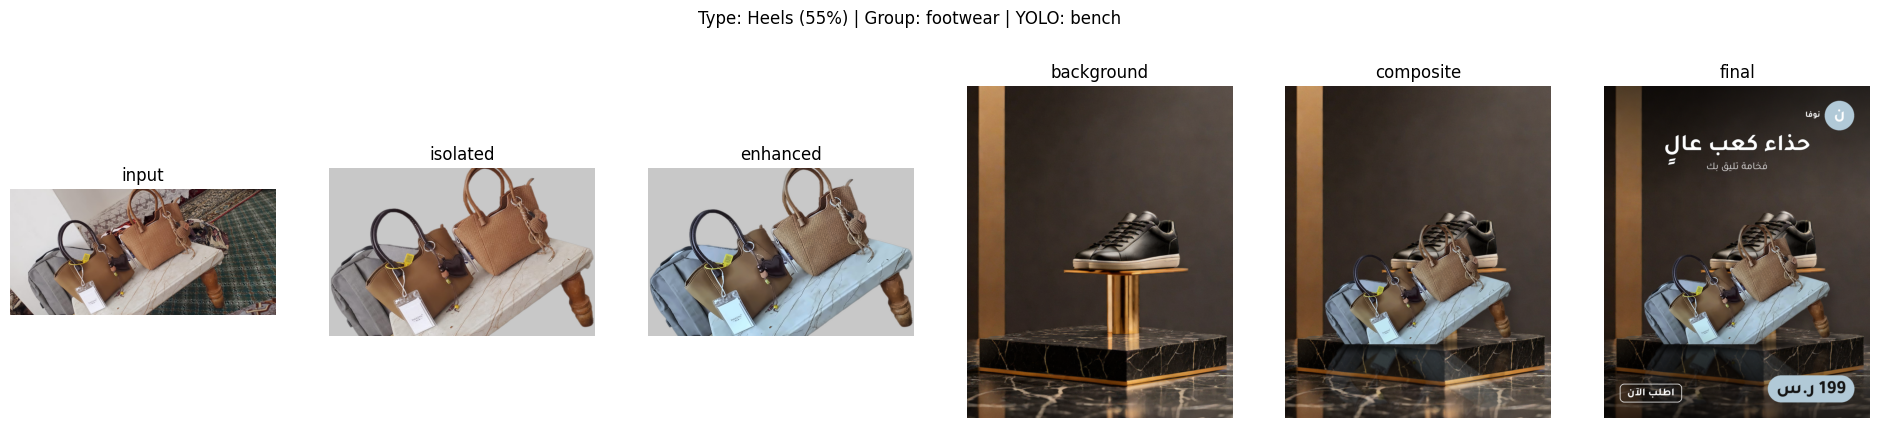

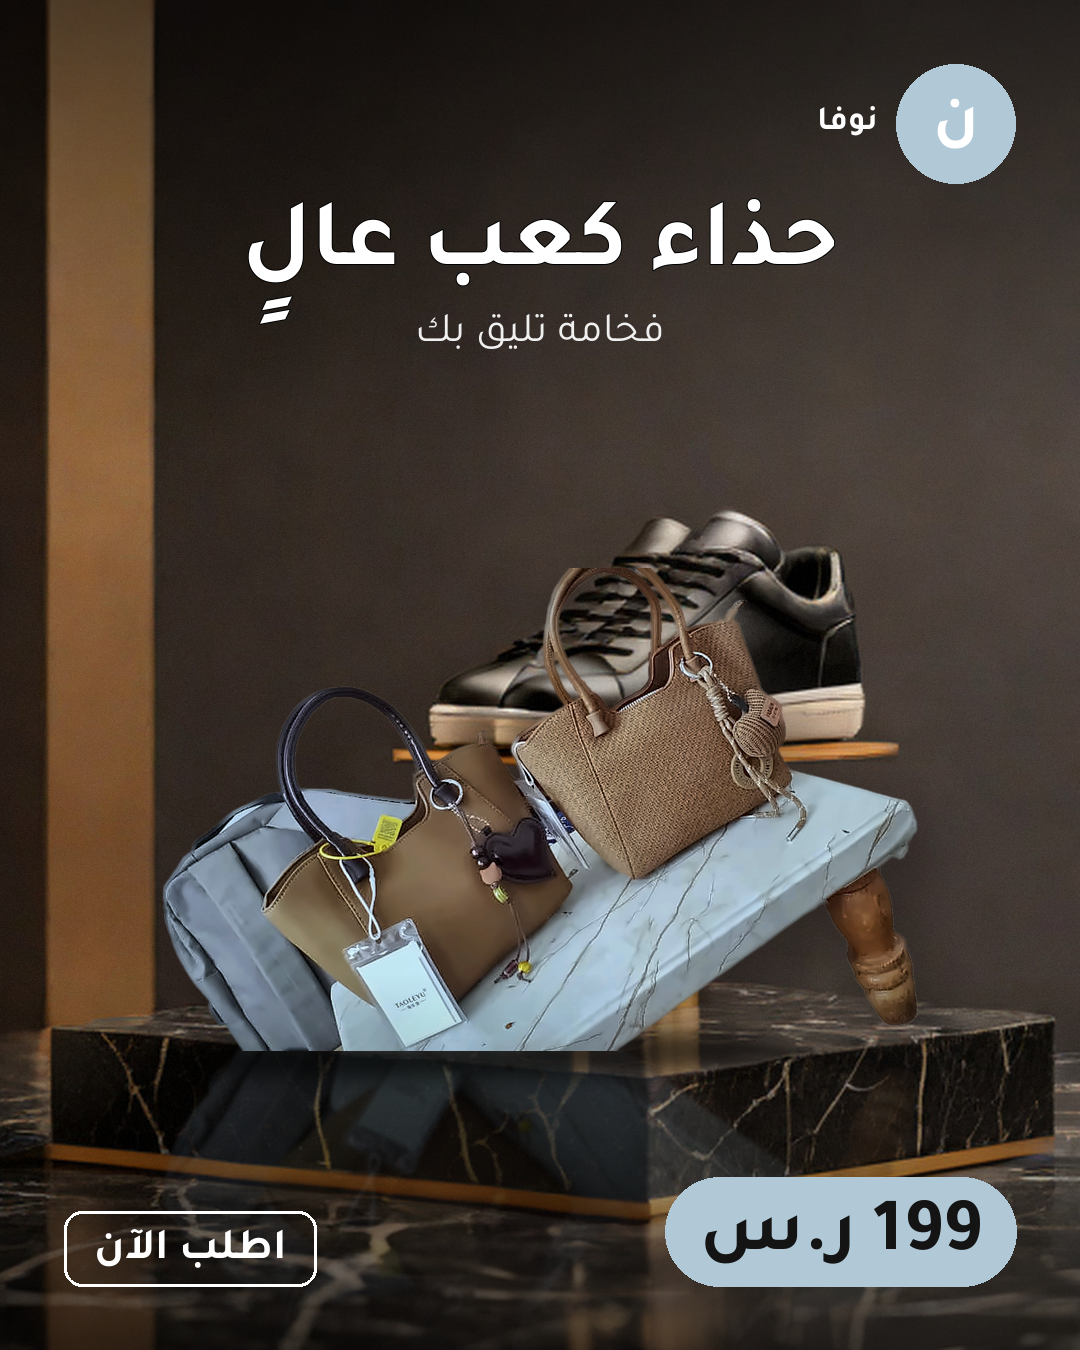

تم الحفظ: /content/ad_ai/outputs/ad_20261125_183258_001.png
[GPU بعد التشغيل] حرة: 15.3 / 15.6 GB


In [16]:
gpu_report("قبل التشغيل")
try:
    from google.colab import files
    print("ارفع صورة منتج (أو اضغط Cancel لاستخدام صورة من البيانات)")
    up = files.upload()
except Exception:
    up = {}

img = Image.open(next(iter(up))).convert("RGB") if up else Image.open(val_df.sample(1, random_state=7).iloc[0].path).convert("RGB")

ad, info, path, steps = create_ad(img, price="199 ر.س", brand="نوفا", style="luxury", seed=123, lang="ar", return_steps=True)
show_steps(steps, info); display(ad); print("تم الحفظ:", path); gpu_report("بعد التشغيل")

## 16) التجربة الافتراضية للملابس (YOLO11-Pose + Perspective Warp + قص حسب الجسم)
تعمل بأفضل شكل مع شخص **واقف ومواجه للكاميرا** وجسمه ظاهر بالكامل أو من الرأس إلى الركبتين. هي تقريب ثنائي الأبعاد؛ لنتائج أدق استخدم نماذج Diffusion مثل IDM-VTON.

In [17]:
def guess_kind(article_type):
    t = article_type.lower()
    if any(k in t for k in ["dress", "kurta", "gown", "saree", "jumpsuit", "nightdress", "tunic"]): return "dress"
    if any(k in t for k in ["jeans", "trouser", "shorts", "skirt", "track", "pant", "leggings", "capri"]): return "bottom"
    return "top"

_pose_model = None
def get_pose_model():
    global _pose_model
    if _pose_model is None: _pose_model = YOLO("yolo11s-pose.pt")     # نقاط الجسم (17 نقطة COCO) — لا يحتاج MediaPipe
    return _pose_model

def _largest(boxes_xyxy): return int(np.argmax([(b[2] - b[0]) * (b[3] - b[1]) for b in boxes_xyxy]))

def virtual_tryon(person_img, garment_rgba, kind="top"):
    person = ImageOps.exif_transpose(person_img).convert("RGB"); arr = np.array(person); H, W = arr.shape[:2]
    r = get_pose_model().predict(person, conf=0.25, verbose=False)[0]
    if r.keypoints is None or len(r.keypoints.xy) == 0 or len(r.boxes) == 0:
        raise ValueError("لم يتم العثور على شخص في الصورة؛ استخدم صورة لشخص واقف ومواجه للكاميرا.")
    k = _largest(r.boxes.xyxy.cpu().numpy())
    pts = r.keypoints.xy[k].cpu().numpy(); cf = r.keypoints.conf[k].cpu().numpy() if r.keypoints.conf is not None else np.ones(17)
    need = {"top": [5, 6, 11, 12], "dress": [5, 6, 13, 14], "bottom": [11, 12, 15, 16]}[kind]
    if (cf[need] < 0.3).any():
        raise ValueError("جزء من الجسم المطلوب غير ظاهر بوضوح (الكتفان/الوركان/الركبتان). استخدم صورة يظهر فيها الجسم كاملاً.")
    P = lambda i: pts[i].astype(np.float32)
    ls, rs = sorted([P(5), P(6)], key=lambda p: p[0]);   lh, rh = sorted([P(11), P(12)], key=lambda p: p[0])
    lk, rk = sorted([P(13), P(14)], key=lambda p: p[0]); la, ra = sorted([P(15), P(16)], key=lambda p: p[0])
    sw = float(np.linalg.norm(rs - ls)); ox = np.array([sw * 0.28, 0]); oy = np.array([0, sw * 0.12])
    if kind == "bottom":  dst = [lh - ox*0.6 - oy*0.5, rh + ox*0.6 - oy*0.5, ra + ox*0.5, la - ox*0.5]
    elif kind == "dress": dst = [ls - ox - oy, rs + ox - oy, rk + ox*0.8, lk - ox*0.8]
    else:                 dst = [ls - ox - oy, rs + ox - oy, rh + ox*0.5 + oy*0.8, lh - ox*0.5 + oy*0.8]

    garment_rgba = garment_rgba.convert("RGBA"); bb = garment_rgba.split()[3].point(lambda v: 255 if v > 10 else 0).getbbox()
    if bb: garment_rgba = garment_rgba.crop(bb)       # قص الحواف الشفافة ليتطابق أعلى القطعة مع الكتفين
    g = np.array(garment_rgba); gh, gw = g.shape[:2]
    M = cv2.getPerspectiveTransform(np.float32([[0, 0], [gw, 0], [gw, gh], [0, gh]]), np.float32(dst))
    warped = cv2.warpPerspective(g, M, (W, H), flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_CONSTANT, borderValue=(0, 0, 0, 0))
    a = cv2.GaussianBlur(warped[..., 3], (5, 5), 0).astype(np.float32) / 255

    try:      # قصّ القطعة داخل صورة الجسم (مع هامش) كي لا تخرج عنه — من قناع YOLO للأشخاص
        rp = yolo.predict(person, conf=0.25, classes=[0], verbose=False)[0]
        if rp.masks is not None and len(rp.masks.xy):
            poly = rp.masks.xy[_largest(rp.boxes.xyxy.cpu().numpy())]
            sil = np.zeros((H, W), np.uint8); cv2.fillPoly(sil, [np.round(poly).astype(np.int32)], 1)
            sil = cv2.dilate(sil, np.ones((int(sw * 0.15) | 1,) * 2, np.uint8))
            a = a * cv2.GaussianBlur(sil.astype(np.float32), (9, 9), 0)
    except Exception as e:
        print("تخطي قص الجسم:", str(e)[:80])

    gray = cv2.GaussianBlur(cv2.cvtColor(arr, cv2.COLOR_RGB2GRAY).astype(np.float32), (0, 0), 25)
    shade = np.clip(0.75 + 0.25 * gray / (gray.mean() + 1e-6), 0.7, 1.15)[..., None]
    out = arr * (1 - a[..., None]) + np.clip(warped[..., :3] * shade, 0, 255) * a[..., None]
    return Image.fromarray(out.astype(np.uint8))

ارفع صورة قطعة الملابس (أو اضغط Cancel لاستخدام عينة من البيانات):


Saving images (1).jpeg to images (1) (1).jpeg
ارفع صورة شخص واقف ومواجه للكاميرا:


Saving images.jpeg to images.jpeg


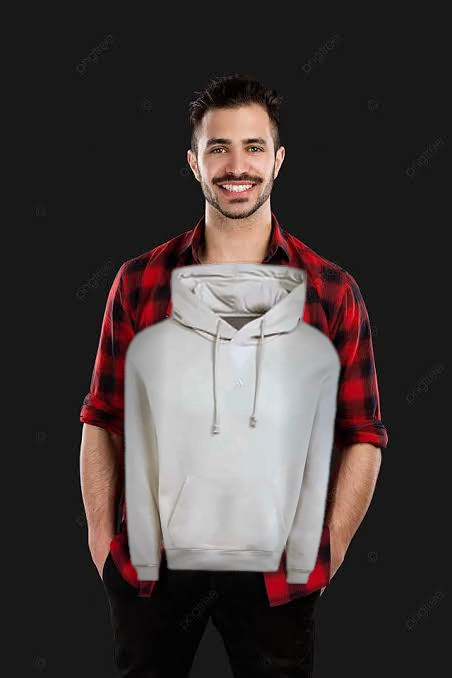

In [18]:
GARMENT_KIND = "top"      # top / dress / bottom — يُستخدم عند رفع صورة الملابس الخاصة بك

def _load_garment():
    try:
        from google.colab import files
        print("ارفع صورة قطعة الملابس (أو اضغط Cancel لاستخدام عينة من البيانات):")
        up = files.upload()
        if up: return Image.open(next(iter(up))).convert("RGB"), GARMENT_KIND
    except Exception:
        pass
    if "df" in globals():
        row = df[df.group == "clothing"].sample(1, random_state=3).iloc[0]
        print("عينة من البيانات:", row.articleType, "→", TYPE_AR.get(row.articleType, ""))
        return Image.open(row.path).convert("RGB"), guess_kind(row.articleType)
    raise RuntimeError("ارفع صورة ملابس، أو شغّل خلايا تجهيز البيانات (القسم 5) أولاً.")

garment_img, kind = _load_garment()
cloth = enhance_product(isolate_product(garment_img))
try:
    from google.colab import files
    print("ارفع صورة شخص واقف ومواجه للكاميرا:")
    up = files.upload(); person = Image.open(next(iter(up)))
    res_img = virtual_tryon(person, cloth, kind); display(res_img)
    p = WORK / "outputs" / f"tryon_{RUN_ID}.png"; res_img.save(p); drive_copy(p, "ads")
except Exception as e:
    print("تعذرت التجربة:", type(e).__name__, "-", e)

## 17) واجهة تفاعلية عربية (Gradio)

In [ ]:
import gradio as gr

STYLE_CHOICES = [("فخم", "luxury"), ("بسيط", "minimal"), ("صيفي", "summer"), ("نيون", "neon"), ("طبيعة", "nature")]
SIZE_CHOICES = [("إنستغرام 4:5", "Instagram 4:5"), ("مربع 1:1", "Square 1:1"), ("ستوري 9:16", "Story 9:16")]
LANG_CHOICES = [("العربية", "ar"), ("English", "en")]

def _need(*names):
    miss = [n for n in names if n not in globals()]
    if miss: raise gr.Error("شغّل الخلايا السابقة أولاً بالترتيب. الناقص: " + ", ".join(miss))

def _rgb(arr): return Image.fromarray(arr).convert("RGB")

def ui_ad(image, title, tagline, price, cta, brand, style, fmt, logo, lang, ar_digits):
    _need("create_ad", "clf", "SEG_SESSION")
    if image is None: raise gr.Error("ارفع صورة المنتج أولاً ثم اضغط Submit")
    try:
        lg = Image.fromarray(logo) if logo is not None else None
        ad, info, path = create_ad(_rgb(image), title, tagline, price, cta, brand, lg, style, SIZES[fmt], lang=lang, ar_digits=ar_digits)
    except gr.Error: raise
    except Exception as e:
        import traceback; traceback.print_exc(); raise gr.Error(f"{type(e).__name__}: {str(e)[:250]}")
    ar_name = TYPE_AR.get(info["type"], info["type"])
    return ad, str(path), f"النوع: {ar_name} ({info['confidence']:.0%}) | المجموعة: {GROUP_AR.get(info['group'], '')} | YOLO: {info['coco']}"

ad_ui = gr.Interface(
    ui_ad,
    [gr.Image(label="صورة المنتج"), gr.Textbox(label="العنوان (اتركه فارغاً للتوليد التلقائي)"), gr.Textbox(label="الشعار الترويجي"),
     gr.Textbox(label="السعر (مثال: 199 ر.س)"), gr.Textbox(label="نص الزر"), gr.Textbox(label="اسم العلامة", value="نوفا"),
     gr.Dropdown(STYLE_CHOICES, value="luxury", label="النمط"), gr.Dropdown(SIZE_CHOICES, value="Instagram 4:5", label="المقاس"),
     gr.Image(label="الشعار (اختياري)"), gr.Radio(LANG_CHOICES, value="ar", label="لغة الإعلان"), gr.Checkbox(label="أرقام عربية (١٢٣)")],
    [gr.Image(label="الإعلان"), gr.File(label="تنزيل"), gr.Textbox(label="التحليل")], title="مولّد الإعلانات الذكي", flagging_mode="never")

def ui_tryon(person, garment, kind):
    _need("virtual_tryon", "isolate_product", "enhance_product")
    if person is None or garment is None: raise gr.Error("ارفع صورة الشخص وصورة قطعة الملابس معاً ثم اضغط Submit")
    try:
        cloth = enhance_product(isolate_product(_rgb(garment)))
        return virtual_tryon(_rgb(person), cloth, kind)
    except Exception as e:
        import traceback; traceback.print_exc(); raise gr.Error(f"{type(e).__name__}: {str(e)[:250]}")

tryon_ui = gr.Interface(ui_tryon, [gr.Image(label="صورة الشخص"), gr.Image(label="صورة قطعة الملابس"),
                        gr.Dropdown([("علوي", "top"), ("فستان", "dress"), ("سفلي", "bottom")], value="top", label="النوع")],
                        gr.Image(label="النتيجة"), title="التجربة الافتراضية", flagging_mode="never")

RTL_CSS = ".gradio-container{direction:rtl;text-align:right} textarea,input{direction:rtl}"
try:
    app = gr.TabbedInterface([ad_ui, tryon_ui], ["الإعلان", "التجربة الافتراضية"], css=RTL_CSS)
except TypeError:
    app = gr.TabbedInterface([ad_ui, tryon_ui], ["الإعلان", "التجربة الافتراضية"])
UI_DEBUG = True     # True: تظهر أخطاء الواجهة في مخرجات الخلية (والخلية تبقى تعمل؛ اضغط ■ لإيقافها عند الانتهاء)
print("استخدم الرابط الذي سيظهر الآن — الروابط القديمة لا تعمل بعد إعادة تشغيل الجلسة. في كل تبويب اضغط Submit بعد رفع الصور.")
app.launch(share=True, debug=UI_DEBUG, show_error=True)

استخدم الرابط الذي سيظهر الآن — الروابط القديمة لا تعمل بعد إعادة تشغيل الجلسة. في كل تبويب اضغط Submit بعد رفع الصور.
Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://d10157184916902c64.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/gradio/queueing.py", line 870, in process_events
    response = await route_utils.call_process_api(
               ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
    ...<6 lines>...
    )
    ^
  File "/usr/local/lib/python3.13/dist-packages/gradio/route_utils.py", line 418, in call_process_api
    output = await app.get_blocks().process_api(
             ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
    ...<12 lines>...
    )
    ^
  File "/usr/local/lib/python3.13/dist-packages/gradio/blocks.py", line 2698, in process_api
    result = await self.call_function(
             ^^^^^^^^^^^^^^^^^^^^^^^^^
    ...<9 lines>...
    )
    ^
  File "/usr/local/lib/python3.13/dist-packages/gradio/blocks.py", line 1963, in call_function
    prediction = await anyio.to_thread.run_sync(  # type: ignore
                 ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
        fn, *processed_input, limiter=self.limiter
        ^^^^^^^^^^^^^^

## 18) 💾 حفظ كل النتائج في Google Drive قبل إنهاء الجلسة
الإعلانات والنماذج تُنسخ تلقائيًا فور إنتاجها، لكن **شغّل هذه الخلية قبل إغلاق الجلسة** لمزامنة كل شيء وإنشاء نسخة ZIP. (Colab لا يوفّر خطّاف إغلاق موثوقًا، لذلك الحفظ الفوري بعد كل نتيجة هو الضمان الحقيقي.)

In [ ]:
def save_all_to_drive(make_zip=True, finish=False):
    # finish=True: يفرغ كاش Drive ويفصله (استخدمه آخر شيء قبل إغلاق الجلسة)
    if DRIVE_DIR is None: mount_drive()
    if DRIVE_DIR is None: print("❌ تعذر الوصول إلى Drive."); return
    run_dir = DRIVE_DIR / "runs" / RUN_ID; run_dir.mkdir(parents=True, exist_ok=True)
    for sub in ("ads", "models"): (DRIVE_DIR / sub).mkdir(parents=True, exist_ok=True)
    out_dir = WORK / "outputs"
    shutil.copytree(out_dir, run_dir / "outputs", dirs_exist_ok=True)                  # كل الإعلانات + ملفات JSON
    for f in list(WORK.glob("*.pt")) + list(WORK.glob("*.json")): drive_copy(f, "models")  # النموذج والمقاييس
    for f in out_dir.glob("*.png"): drive_copy(f, "ads")
    if make_zip and any(out_dir.iterdir()):
        zp = run_dir / f"ads_{RUN_ID}.zip"
        with zipfile.ZipFile(zp, "w", zipfile.ZIP_DEFLATED) as z:
            for f in out_dir.iterdir(): z.write(f, f.name)
        print("🗜️ نسخة ZIP:", zp)
    os.sync()
    n = len(list(out_dir.glob("*.png")))
    print(f"✅ تم الحفظ في: {DRIVE_DIR}\n   إعلانات هذه الجلسة: {n} | النماذج: {[p.name for p in (DRIVE_DIR / 'models').iterdir()]}")
    if finish:
        from google.colab import drive
        drive.flush_and_unmount(); print("🔌 تمت المزامنة وفصل Drive. يمكنك إغلاق الجلسة بأمان.")

save_all_to_drive(make_zip=True, finish=False)     # ← غيّر finish إلى True عند الانتهاء النهائي